# Crystal structures and simulated powder XRD

Using `crystallo` to:

1. compare densities and packing fractions of common metals and semiconductors,
2. simulate Cu K$\alpha$ powder patterns and see the FCC, BCC and diamond selection rules,
3. show how a two-element basis (NaCl vs. CsCl) changes which reflections appear.

Intensities use a constant form factor and the Lorentz-polarisation factor, so they're qualitative. Peak *positions* are exact for the given lattice constants.

In [1]:
import sys
sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
import crystallo as cr

## 1. Densities and packing fractions

In [2]:
materials = [
    cr.fcc("Cu", 3.615), cr.fcc("Al", 4.0495), cr.fcc("Au", 4.0782),
    cr.bcc("Fe", 2.8665), cr.bcc("W", 3.1652), cr.diamond("Si", 5.431),
    cr.diamond("Ge", 5.658), cr.hcp("Mg", 3.209, 5.211),
]
print(f"{'material':14s} {'a (A)':>7s} {'Z':>3s} {'density g/cm3':>14s} {'packing':>8s}")
for m in materials:
    print(f"{m.name:14s} {m.lattice.a:7.4f} {m.atoms_per_cell:3d} {m.density:14.3f} {m.packing_fraction():8.3f}")

material         a (A)   Z  density g/cm3  packing
Cu (fcc)        3.6150   4          8.935    0.740
Al (fcc)        4.0495   4          2.699    0.740
Au (fcc)        4.0782   4         19.289    0.740
Fe (bcc)        2.8665   2          7.874    0.680
W (bcc)         3.1652   2         19.254    0.680
Si (diamond)    5.4310   8          2.329    0.340
Ge (diamond)    5.6580   8          5.327    0.340
Mg (hcp)        3.2090   2          1.737    0.745


## 2. Powder patterns with Cu K$\alpha_1$ ($\lambda$ = 1.5406 Å)

FCC allows reflections with all-odd or all-even indices, BCC needs $h+k+l$ even, and diamond also removes the all-even planes with $h+k+l = 4n+2$.

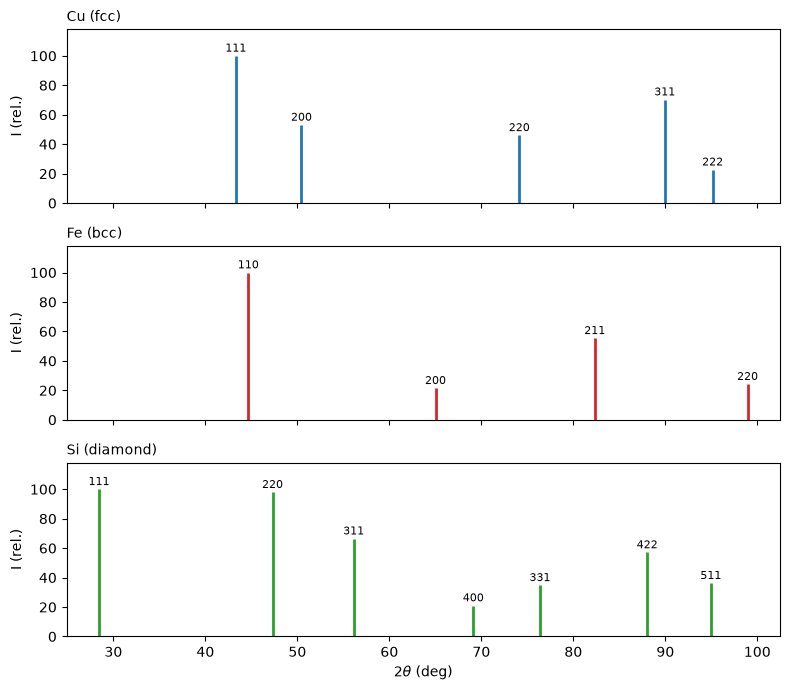

In [3]:
def stick_plot(ax, crystal, color):
    peaks = crystal.powder_pattern(two_theta_max=100)
    ax.vlines([p.two_theta for p in peaks], 0, [p.intensity for p in peaks], color=color, lw=2)
    for p in peaks:
        if p.intensity > 4:
            ax.annotate("".join(map(str, p.hkl)), (p.two_theta, p.intensity),
                        textcoords="offset points", xytext=(0, 3), ha="center", fontsize=8)
    ax.set_ylim(0, 118); ax.set_ylabel("I (rel.)"); ax.set_title(crystal.name, loc="left", fontsize=10)

fig, axes = plt.subplots(3, 1, figsize=(8, 7), sharex=True)
for ax, crys, col in zip(axes, [cr.fcc("Cu", 3.615), cr.bcc("Fe", 2.8665), cr.diamond("Si", 5.431)], ["C0", "C3", "C2"]):
    stick_plot(ax, crys, col)
axes[-1].set_xlabel(r"2$\theta$ (deg)")
plt.tight_layout(); plt.show()

In [4]:
for p in cr.diamond("Si", 5.431).powder_pattern(two_theta_max=90):
    print(f"Si {''.join(map(str, p.hkl)):>4s}  d = {p.d:6.4f} A  2theta = {p.two_theta:6.2f}  mult = {p.multiplicity:2d}  I = {p.intensity:5.1f}")

Si  111  d = 3.1356 A  2theta =  28.44  mult =  8  I = 100.0
Si  220  d = 1.9202 A  2theta =  47.30  mult = 12  I =  98.0
Si  311  d = 1.6375 A  2theta =  56.12  mult = 24  I =  66.4
Si  400  d = 1.3578 A  2theta =  69.13  mult =  6  I =  21.0
Si  331  d = 1.2460 A  2theta =  76.38  mult = 24  I =  34.8
Si  422  d = 1.1086 A  2theta =  88.03  mult = 24  I =  57.1


## 3. Effect of a two-atom basis

Na and Cl scatter with different strengths, so the NaCl (111) reflection survives but is weak. In CsCl the (100) reflection appears, which a BCC lattice of identical atoms would forbid.

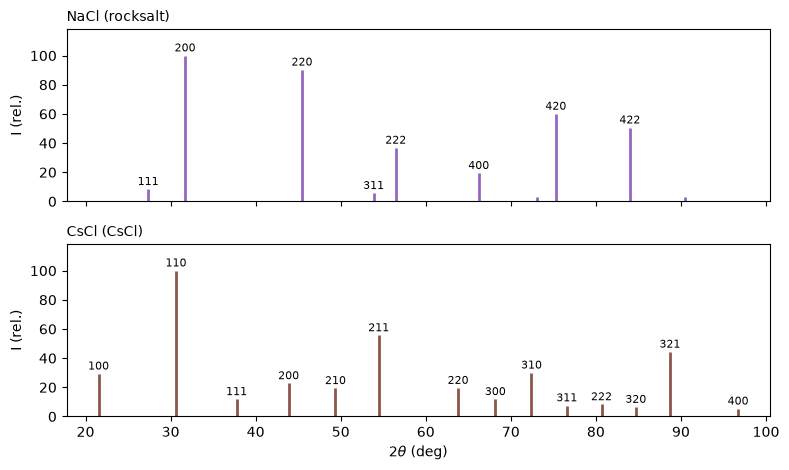

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(8, 4.8), sharex=True)
stick_plot(axes[0], cr.rocksalt("Na", "Cl", 5.640), "C4")
stick_plot(axes[1], cr.cesium_chloride("Cs", "Cl", 4.123), "C5")
axes[-1].set_xlabel(r"2$\theta$ (deg)")
plt.tight_layout(); plt.show()

## 4. Peak shift with lattice parameter

Thermal expansion or alloying changes $a$, which shifts every peak. Here is the Cu (111) position over a ±1 % change in $a$:

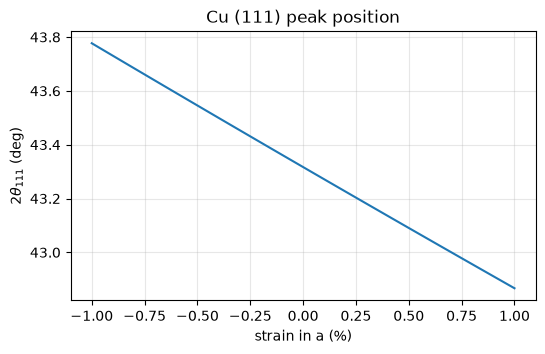

In [6]:
a0 = 3.615
a_vals = a0 * np.linspace(0.99, 1.01, 50)
tt = [cr.Lattice.cubic(a).bragg_two_theta(1, 1, 1) for a in a_vals]
plt.figure(figsize=(6, 3.5))
plt.plot((a_vals / a0 - 1) * 100, tt)
plt.xlabel("strain in a (%)"); plt.ylabel(r"2$\theta_{111}$ (deg)"); plt.title("Cu (111) peak position")
plt.grid(alpha=0.3); plt.show()